In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Configuração Estética
# plt.style.use('ggplot')
#plt.rcParams['figure.figsize'] = (14, 8)

#Dados (Johns Hopkins University)
# URL = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
# df = pd.read_csv(URL)

#comentar sobre a origem dos dados aqui
df = pd.read_csv('time_series_covid19_confirmed_global.csv')

# 2. Filtrar França (Soma das províncias)
france_data = df[df['Country/Region'] == 'France'].iloc[:, 4:].sum(axis=0)
france_data.index = pd.to_datetime(france_data.index, errors='coerce')

# 3. Vetores Principais
y_real_acc = france_data.values.astype(float) # Casos Totais (C)
x_days = np.arange(len(y_real_acc))
N = 67_500_000 

# Calculamos novos casos (Hoje - Ontem)
y_daily = np.diff(y_real_acc, prepend=0)

# ESTIMATIVA DE CASOS ATIVOS REAIS (Proxy para comparação)
# Assumimos que Ativos = Soma dos novos casos dos últimos 14 dias
y_real_active = pd.Series(y_daily).rolling(window=14).sum().fillna(0).values

print(f"Dados carregados: {len(x_days)} dias de pandemia.")
print(f"Total acumulado final: {y_real_acc[-1]:,.0f}")

print(y_real_acc[0])

Dados carregados: 1143 dias de pandemia.
Total acumulado final: 39,866,718
0.0


C:\Users\pedro\AppData\Local\Temp\ipykernel_5972\1393661498.py:19: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  france_data.index = pd.to_datetime(france_data.index, errors='coerce')


In [ ]:

def sir_discrete(t, beta, gamma, return_full=False):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    
    
    I[0] = max(y_real_acc[0], 1)
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        
        S[i+1] = max(0, S[i] - new_inf)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = R[i] + new_rec
        
    if return_full: return S, I, R, (I + R)
    return I + R

def sirs_discrete(t, beta, gamma, xi, return_full=False):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    C = np.zeros(len(t))
    
    I[0] = max(y_real_acc[0], 1)
    C[0] = max(y_real_acc[0], 1)
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):

        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i] # Perda de imunidade
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        C[i+1] = C[i] + new_inf
        
    if return_full: return S, I, R, C
    return C

num_nodes = 5 # Nós de controle para o Beta Variável
x_nodes = np.linspace(0, len(x_days), num_nodes)

def sirs_dynamic_discrete(t, gamma, xi, *betas_array, return_full=False):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    C = np.zeros(len(t))
    
    I[0] = max(y_real_acc[0], 1)
    C[0] = max(y_real_acc[0], 1)
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        # Interpolação do Beta para o dia atual
        beta_t = np.interp(i, x_nodes, betas_array)
        
        new_inf = (beta_t * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        C[i+1] = C[i] + new_inf
        
    if return_full: return S, I, R, C
    return C

In [64]:
print("Iniciando otimização (com travas biológicas para Gamma)...")

# --- 1. Ajuste SIR ---
# Restrição: Gamma entre 0.04 (25 dias) e 0.2 (5 dias)
# Bounds formato: ([min_beta, min_gamma], [max_beta, max_gamma])
popt_sir, _ = curve_fit(sir_discrete, x_days, y_real_acc, 
                        p0=[0.1, 0.1], 
                        bounds=([0.0, 0.04], [5.0, 0.2]))

# --- 2. Ajuste SIRS ---
# Bounds: ([min_beta, min_gamma, min_xi], [max_beta, max_gamma, max_xi])
popt_sirs, _ = curve_fit(sirs_discrete, x_days, y_real_acc, 
                         p0=[0.1, 0.1, 0.001], 
                         bounds=([0.0, 0.04, 0.0], [5.0, 0.2, 1.0]))

# --- 3. Ajuste DINÂMICO ---
# Aqui aplicamos a correção principal.
# Chutes iniciais
init_dyn = [0.08, 0.005] + [0.15] * num_nodes

# Limites Inferiores (Gamma > 0.04) 25 dias
low_dyn = [0.04, 0.0] + [0.0] * num_nodes
# Limites Superiores (Gamma < 0.2) 5 dias
up_dyn = [0.2, 1.0] + [5.0] * num_nodes

popt_dyn, _ = curve_fit(sirs_dynamic_discrete, x_days, y_real_acc, 
                        p0=init_dyn, 
                        bounds=(low_dyn, up_dyn), 
                        maxfev=30000) # Aumentamos iterações para garantir convergência

print(f"Gamma encontrado no Dinâmico: {popt_dyn[0]:.4f} (Duração média: {1/popt_dyn[0]:.1f} dias)")

Iniciando otimização (com travas biológicas para Gamma)...
Gamma encontrado no Dinâmico: 0.1097 (Duração média: 9.1 dias)


In [65]:
# Agora chamamos as mesmas funções com return_full=True e os parâmetros otimizados

# SIR
S_sir, I_sir, R_sir, C_sir = sir_discrete(x_days, *popt_sir, return_full=True)

# SIRS
S_sirs, I_sirs, R_sirs, C_sirs = sirs_discrete(x_days, *popt_sirs, return_full=True)

# Dinâmico
S_dyn, I_dyn, R_dyn, C_dyn = sirs_dynamic_discrete(x_days, *popt_dyn, return_full=True)

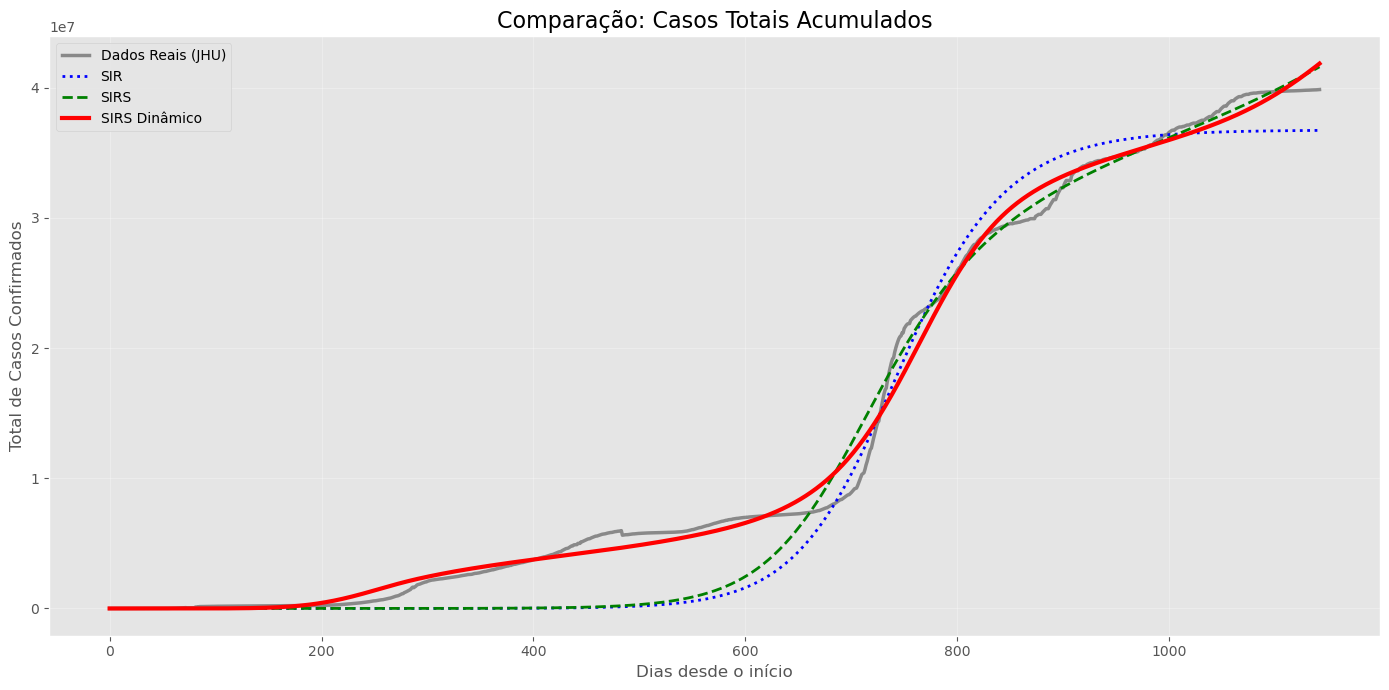

In [66]:
plt.figure(figsize=(14, 7))
plt.title("Comparação: Casos Totais Acumulados", fontsize=16)

# Dados reais
plt.plot(x_days, y_real_acc, color='black', label='Dados Reais (JHU)', alpha=0.4, linewidth=2.5)

# Modelos
plt.plot(x_days, C_sir, label='SIR', linestyle=':', color='blue', linewidth=2)
plt.plot(x_days, C_sirs, label='SIRS', linestyle='--', color='green', linewidth=2)
plt.plot(x_days, C_dyn, label='SIRS Dinâmico', color='red', linewidth=3)

plt.ylabel("Total de Casos Confirmados")
plt.xlabel("Dias desde o início")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.tight_layout()
plt.show()

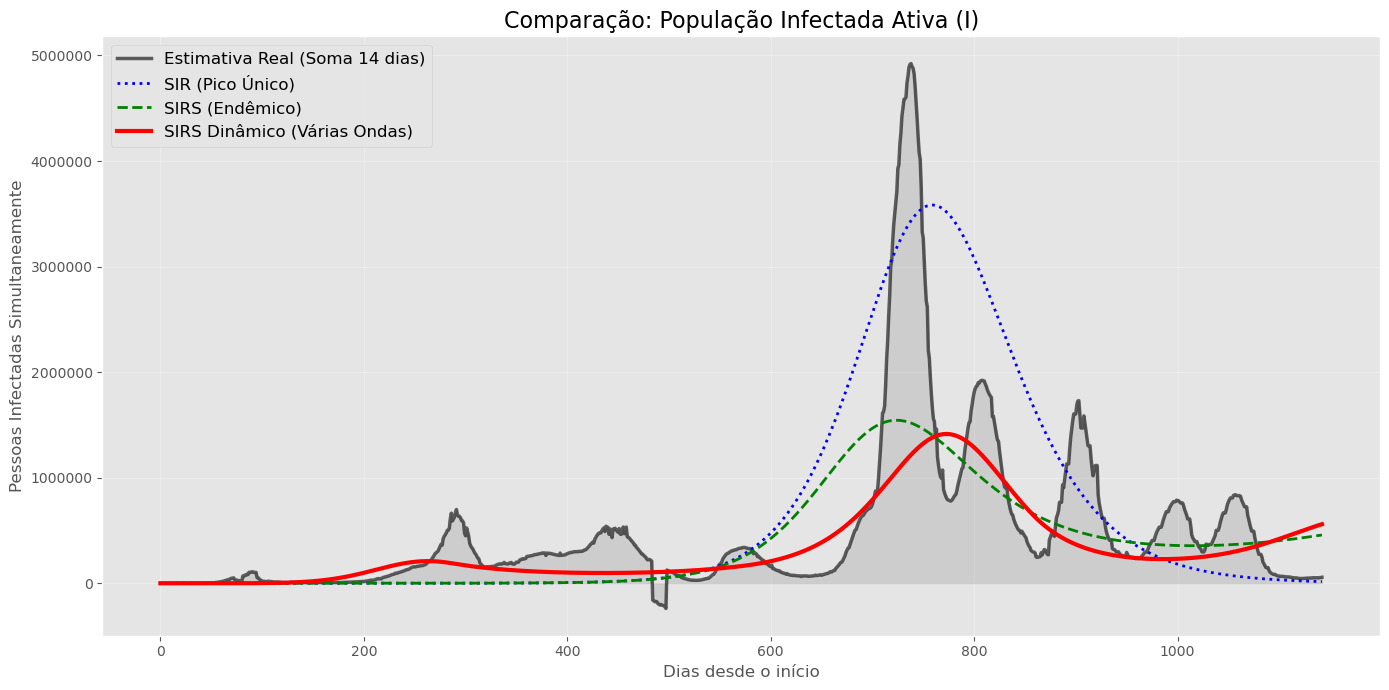

In [67]:
# --- PLOTAGEM ---
plt.figure(figsize=(14, 7))
plt.title("Comparação: População Infectada Ativa (I)", fontsize=16)

# 1. A CURVA REAL (Mantida como referência principal)
# Usamos uma linha preta sólida para mostrar claramente a "curva" real
plt.plot(x_days, y_real_active, color='black', alpha=0.6, label='Estimativa Real (Soma 14 dias)', linewidth=2.5)
# Uma sombra leve para dar volume
plt.fill_between(x_days, y_real_active, color='black', alpha=0.1)

# 2. OS MODELOS
plt.plot(x_days, I_sir, label='SIR (Pico Único)', linestyle=':', color='blue', linewidth=2)
plt.plot(x_days, I_sirs, label='SIRS (Endêmico)', linestyle='--', color='green', linewidth=2)
plt.plot(x_days, I_dyn, label='SIRS Dinâmico (Várias Ondas)', color='red', linewidth=3) # Destaque no dinâmico

# Detalhes
plt.ylabel("Pessoas Infectadas Simultaneamente")
plt.xlabel("Dias desde o início")
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='plain', axis='y') # Remove notação científica (1e6)

plt.tight_layout()
plt.show()

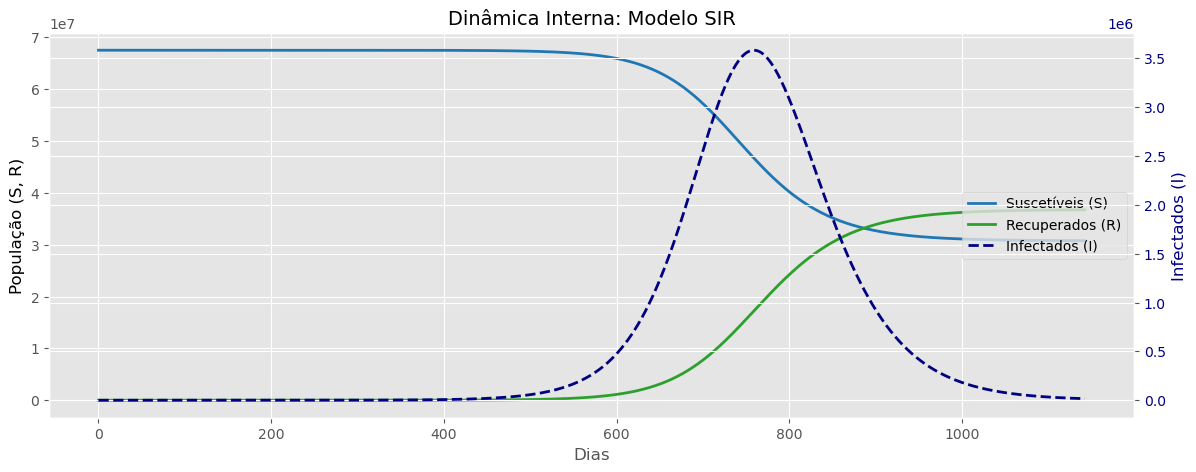

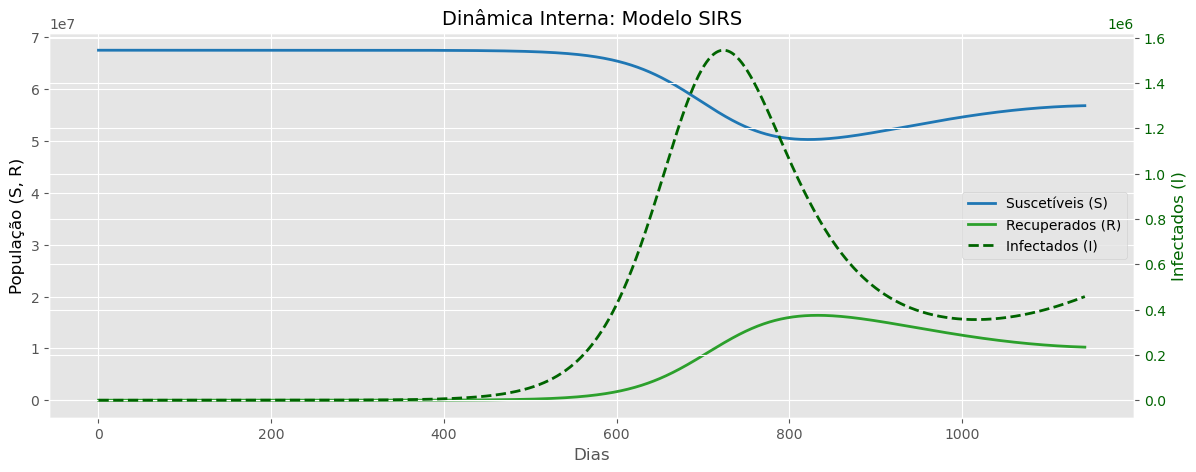

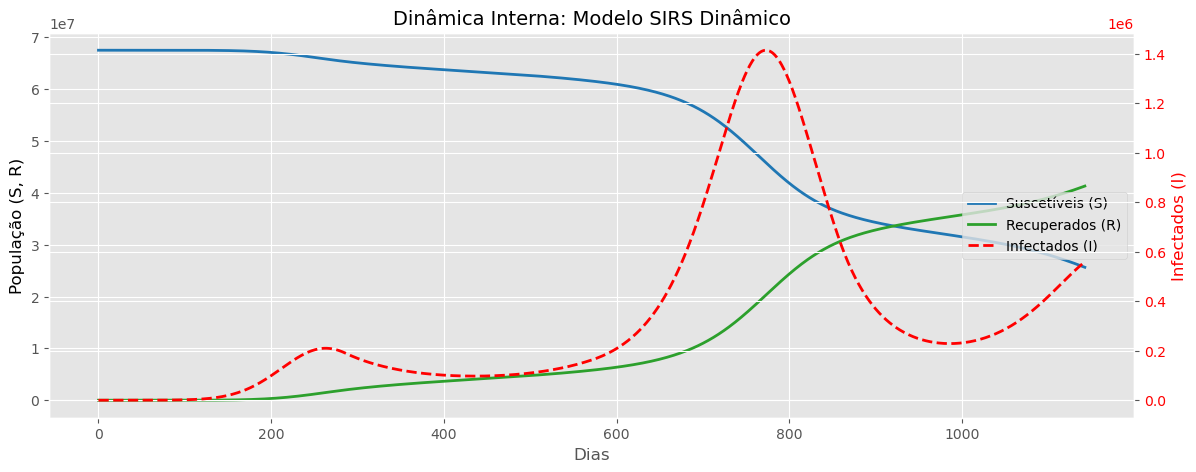

In [68]:
def plot_dynamics(model_name, S, I, R, color_i):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax1.set_title(f"Dinâmica Interna: {model_name}", fontsize=14)
    
    # Eixo Esquerdo: S e R
    ax1.set_xlabel("Dias")
    ax1.set_ylabel("População (S, R)", color='black')
    line1, = ax1.plot(x_days, S, label='Suscetíveis (S)', color='tab:blue', linewidth=2)
    line2, = ax1.plot(x_days, R, label='Recuperados (R)', color='tab:green', linewidth=2)
    
    # Eixo Direito: I
    ax2 = ax1.twinx()
    line3, = ax2.plot(x_days, I, label='Infectados (I)', color=color_i, linewidth=2, linestyle='--')
    ax2.set_ylabel("Infectados (I)", color=color_i)
    ax2.tick_params(axis='y', labelcolor=color_i)
    
    # Legenda Unificada
    lines = [line1, line2, line3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')
    
    plt.show()

plot_dynamics("Modelo SIR", S_sir, I_sir, R_sir, 'navy')
plot_dynamics("Modelo SIRS", S_sirs, I_sirs, R_sirs, 'darkgreen')
plot_dynamics("Modelo SIRS Dinâmico", S_dyn, I_dyn, R_dyn, 'red')